In [1]:
import numpy as np
import torch
import os,glob
from collections import OrderedDict
from torchvision import datasets, transforms
from attrdict import AttrDict
# from train_base import  (setup_randomness,
#                          setup_dataset,
#                          setup_model,
#                          eval_trainedmodel,
#                     )

from train_v3_base import  (setup_randomness,
                           setup_dataset,
                           setup_model,
                           #eval_trainedmodel,
                    )


In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"   # see issue #152
os.environ["CUDA_VISIBLE_DEVICES"]="0"

In [3]:
trainset,contexset,oodset='cifar10', 'cifar100','svhn'




In [4]:
#results_path = './results/final_{}_{}'.format(trainset,contexset)
#results_path = './results/final_{}_{}'.format(trainset,contexset)
#results_path = './results/{}_{}'.format(trainset,contexset)
#results_path = './results/{}_{}'.format(trainset,contexset)


#results_path = './results/{}_{}'.format(trainset,contexset)
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v121'))

# results_path = './results/vessl_{}_{}_230904'.format(trainset,contexset)
# results_path_list = sorted(glob.glob(results_path + '/*/'))

results_path = './results/{}_{}'.format(trainset,contexset)
#results_path_list = sorted(glob.glob(results_path + '/*_v9/'))
#results_path_list = sorted(glob.glob(results_path + '/*_v10/'))
#results_path_list = sorted(glob.glob(results_path + '/*_v11/'))
results_path_list = sorted(glob.glob(results_path + '/*_v12/'))

#results_path = './results/{}_{}_230525'.format(trainset,contexset)



results_path

'./results/cifar10_cifar100'

In [6]:
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v151'))

#results_path_list.sort(key=os.path.getmtime,reverse=True)
results_path_list.sort(key=os.path.getmtime)
results_path_list 



['./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.1_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout1.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.1_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.8_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/'

In [6]:
results_path_list = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet18_scalelogstd-8_nepoch200_lr0.1_reglambda0.001_userelregFalse_nfsample1_nexp1_v120',    
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet18_scalelogstd-6_priorstdout5.0_lr0.1_Tmax200_nctset4_reglambda1e-08_nfsample10_mixcontextFalse_topk10_losstypeelbo_nexp1_v120',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameb2resnet18_scalelogstd-6_lr0.1_reglambda1e-08_nfsample10_nexp1_v120',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameb2resnet34_scalelogstd-6_lr0.1_reglambda1e-08_nfsample10_nexp1_v120',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
 ]


results_path_list = [
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout1.0_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout1.0_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout1.0_lr0.1_nctset4_reglambda0.001_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout1.0_lr0.1_nctset4_reglambda0.001_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.0001_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet18_scalelogstd-6_priorstdout10.0_lr0.1_nctset4_reglambda0.0001_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v120',    
]


results_path_list = [
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.75_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',    

#'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
#'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
#'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',
#'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v120',

#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',

#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.75_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.5_lr0.1_nctset4_reglambda0.0_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.75_lr0.1_nctset4_reglambda0.0_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample20_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeiwae_nexp1_v121',
 
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',

'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebma2fbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebma2fbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v121',
]


results_path_list = [
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebma2fbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebma2fbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebma2fbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample2_nepochratio0.8_usepretrainFalse_mixcontextTrue_topk3_losstypeelbo_nexp1_v151',
 ]    

In [7]:
results_path_list = [
 './results/vessl_cifar10_cifar100_230904/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-6_priorstdout10.0_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_losstypeelbo_mixalpha0.01_nexp1_v8/',
 './results/vessl_cifar10_cifar100_230904/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-6_priorstdout10.0_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_losstypeelbo_mixalpha0.1_nexp1_v8/',
 './results/vessl_cifar10_cifar100_230904/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixalpha0.01_nexp1_v8/',
 './results/vessl_cifar10_cifar100_230904/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-6_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample2_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixalpha0.1_nexp1_v8/',
 ]    


In [8]:
## trade-off experiments
results_path_list = [
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-08_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-07_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-06_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-05_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.0001_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.1_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v9/',
 ]    


## investigate effect of regularization: fsvi
modelname = 'fsvi'
results_path_list = [
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-06_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1e-05_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.005_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.05_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.5_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1.0_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 ]    


In [6]:
# results_path_list = [
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
# # './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0005_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
# #  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
# #  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.005_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
# #  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.01_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
# #  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.05_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
#  ]    


## investigate the effect of regularization: bam
modelname = 'bma'
results_path_list = [
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',    
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-05_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0005_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.005_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
]   

## investigate the effect of regularization and different prior std
results_path_list = [
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-05_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout1.0_temppeak0.9_lr0.1_nctset4_reglambda1e-05_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout1.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
'./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout1.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/'    
]
 


In [7]:
## together 
results_path_list = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',    
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda1.0_nfsample10_nepochratio0.8_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v10/',

#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-07_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',    
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-06_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda1e-05_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextFalse_mixalpha0.5_mixselfFalse_nexp1_v11/',
]   


In [5]:
# results_path_list = [
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.8_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.8_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.8_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/'
#  ]    
    
    
    
    
    
#nepochratio .01 and mixalpha .2
## fsvi    
modelname='fsvi'
results_path_list_mixalpha2_fsvi = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/', 
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
 ]

results_path_list_mixalpha5_fsvi = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
 ]        

 
#nepochratio .01 and mixalpha .2
results_path_list_mixalpha8_fsvi = [
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.0001_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',  
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.001_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.01_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbresnet20_scalelogstd-8_priorstdout10.0_nctset4_reglambda0.1_nfsample10_nepochratio0.01_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/', 
 ]        
    

    
    
##bma

modelname='bmafbnn'
results_path_list_mixalpha2_bma = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',    
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.01_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.1_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.2_mixselfFalse_nexp1_v12/',
]


##bma
results_path_list_mixalpha5_bma = [
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.01_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.1_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.5_mixselfFalse_nexp1_v12/',
]


##bma
results_path_list_mixalpha8_bma = [
# './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.0001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',   
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.001_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.01_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',    
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamebmafbresnet20_scalelogstd-8_priorstdout10.0_temppeak0.9_lr0.1_nctset4_reglambda0.1_nfsample10_nepochratio0.8_usepretrainFalse_topk3_losstypeelbo_mixcontextTrue_mixalpha0.8_mixselfFalse_nexp1_v12/',
]




In [6]:
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,           
                         get_entropy,              
                         )

from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict




def eval_trainedmodel(dataloader, model,q_params = None , nfsample=1, topk=3, configs=None):
    assert q_params is not None
    pred_list,label_list,logit_list = [],[],[]    

    model.eval()    
    with torch.no_grad():
        for i, (x, y) in enumerate(dataloader):    
            # predict class            
            outs = model.predict_eval(x.cuda(), nfsample=nfsample, topk=topk)                     

            # compute performance
            logit_list.append(outs.logits.cpu())
            pred_list.append(outs.pred.cpu())
            label_list.append(y.cpu())

            torch.cuda.empty_cache() 
    
    pred_list = torch.cat(pred_list,dim=0)    
    label_list = torch.cat(label_list,dim=0)    
    logit_list = torch.cat(logit_list,dim=1)    
        
    # evaluate model
    outs = AttrDict()
    outs.pred_list = pred_list
    outs.label_list = label_list    
    outs.logit_list = logit_list.transpose(1,0)
    return outs    



def _compute_diversity_ratio(outs , digits=3):
    yhat = outs.logit_list.max(dim=-1)[1]
    nfsample = yhat.shape[-1]

    static_list = []
    for i_yhat in yhat:
        i_yhat_unique,i_yhat_unique_cnt = i_yhat.unique(return_counts=True)
        top1_cnt = i_yhat_unique_cnt.topk(1).values.item()
        majority_cnt = top1_cnt
        not_majority_cnt = nfsample - top1_cnt
        #nfsample
        # majority_cnt = (i_yhat_unique[0] == i_yhat).sum().item()
        # not_majority_cnt = (i_yhat_unique[0] != i_yhat).sum().item()
        #yhat = outs_ood1.logit_list.max(dim=-1)[1]
        #yhat_unique,yhat_unique_cnt = yhat[4].unique(return_counts=True)


        static_list.append( (majority_cnt/nfsample, not_majority_cnt/ nfsample , not_majority_cnt/ majority_cnt) )  #( majority_cnt/nfsample,       not_majority_cnt/ nfsample ,   not_majority_cnt/ majority_cnt )
    
    static_list = np.array(static_list).round(3)
    #return static_list.mean(axis=0).round(digits), static_list.std(axis=0).round(digits)
    return static_list.mean(axis=0).round(digits), ((1/np.sqrt(nfsample))*static_list.std(axis=0)).round(digits)

# With Calibration

## calibaration revision

In [7]:
from attrdict import AttrDict
configs = AttrDict( dataset = AttrDict( trainset = trainset, contextset = contexset, oodset = [oodset] ),
                    train   = AttrDict( nbatch = 128 ),
                    exp     = AttrDict( seeds = '1111')
                )    
trainloader,valloader,testloader,contextloader,oodlist_loader = setup_dataset(configs,fortrain=False) 
oodloader_v1 = oodlist_loader[0]

#configs
#setup_randomness(i_th_saved['configs'].exp.seeds)

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Using downloaded and verified file: /home/becre1776/Datasets/SVHN/train_32x32.mat
Using downloaded and verified file: /home/becre1776/Datasets/SVHN/test_32x32.mat


In [8]:
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,      
                         get_ood_auroc2,     
                         get_entropy,              
                         )


def get_results_from_outs(outs,outs_ood1,n_runs=5,n_splits=2,digits=3):
    
    log_preds, targets  = (outs.pred_list.log()).cpu().data.numpy(), outs.label_list.cpu().data.numpy()
    log_ood1_preds, targets_ood1 = (outs_ood1.pred_list.log()).cpu().data.numpy(), outs_ood1.label_list.cpu().data.numpy()
    
    # log_full1_preds, targets_full1 = np.concatenate([log_preds,log_ood1_preds],axis=0), np.array(list(targets) + list(targets_ood1))
    # targets_fullood1 = np.array(list(np.zeros( log_full1_preds.shape )) + list(np.ones_like(targets_ood1)))
    #targets_fullood2 = np.array(list(np.zeros_like(targets)) + list(np.ones_like(targets_ood2)))
    
    #norm1,norm2 = np.linalg.norm(log_full1_preds[targets_fullood1 == 0],2,axis=1),  np.linalg.norm(log_full1_preds[targets_fullood1 == 1],2,axis=1)
    #print('norm1: {}, norm2: {}'.format(norm1.mean(),norm2.mean()))
    
    # ------------------------------------------------
    # evaluate acc,nll, and, ece
    # ------------------------------------------------        
    acc_runs,nll_runs,ece_runs,aucroc1,aucroc2 = [],[],[],[],[]
    indent1,indent2 = [],[]        
    outdent1,outdent2 = [],[]
    
    for runs in range(n_runs):
        for i, (tr_idx, te_idx) in enumerate(KFold(n_splits=n_splits, shuffle=True).split(log_preds)):
            train_t = ts(log_preds[tr_idx], targets[tr_idx])
            test_lp = apply_t(log_preds[te_idx], train_t)                    
            acc_runs.append( get_acc(np.exp(test_lp), targets[te_idx] ) )
            nll_runs.append( -get_ll(np.exp(test_lp), targets[te_idx]) )
            ece_runs.append( get_ece(np.exp(test_lp), targets[te_idx]) )       
            #aucroc1 = evaluate_aucroc(testloader, oodloader_v1, eval_trainedmodel, model, list(model.parameters()) , thresholds=100)
            #aucroc2 = evaluate_aucroc(testloader, oodloader_v2, eval_trainedmodel, model, list(model.parameters()) , thresholds=100)



            #test_lp = apply_t(log_preds[te_idx], train_t)                  
            test_lp_ood = apply_t(log_ood1_preds[te_idx], train_t)  
            
            test_lp_in_out = np.concatenate([test_lp,test_lp_ood],axis=0)
            #labels_in_out = np.array(list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] )))
            ood_labels = np.array(  list(np.zeros( test_lp.shape[0] )) + list(np.ones(test_lp_ood.shape[0] ) )  )

            
            # aucroc1.append( get_ood_auroc(np.exp(test_full1_lp),[],targets_fullood1[te_idx] ) )       
            aucroc1.append(  get_ood_auroc2(np.exp(test_lp_in_out ), ood_labels  ) )       
                            
            tmp_indent1 =  get_entropy( np.exp(test_lp) )
            tmp_outdent1 = get_entropy( np.exp(test_lp_ood) )
            indent1.append(  tmp_indent1  )
            outdent1.append( tmp_outdent1 )                
            
            
    # ------------------------------------------------
    # evaluate acc,nll, and, ece
    # ------------------------------------------------                        
    #acc,nll,ece = np.mean(acc_runs).round(digits),np.mean(nll_runs).round(digits),np.mean(ece_runs).round(digits)
    acc,nll,ece = np.mean(acc_runs).round(digits),np.mean(nll_runs).round(digits),np.mean(ece_runs).round(digits)                                   
    #aucroc1,aucroc2 = np.mean(aucroc1).round(digits), np.mean(aucroc2).round(digits)
    aucroc1 = np.mean(aucroc1).round(digits)
    indent1,outdent1 = np.mean(indent1).round(digits),np.mean(outdent1).round(digits)
    #print(acc,nll,ece,aucroc1,aucroc2)
    
    
    # evaluate functional diversity
    fdiv_in = _compute_diversity_ratio(outs , digits=3)
    fdiv_out = _compute_diversity_ratio(outs_ood1 , digits=3)
    
    fdivin = fdiv_in[0][1], fdiv_in[1][1]
    fdivout = fdiv_out[0][1], fdiv_out[1][1]
    
    rfdivin = fdiv_in[0][2],fdiv_in[1][2]        
    rfdivout = fdiv_out[0][2],fdiv_out[1][2]
    
    return acc,nll,ece,aucroc1,indent1,outdent1,fdivin,fdivout,rfdivin,rfdivout



#model_spec


In [9]:
import copy
from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict
from attrdict import AttrDict

def _get_modelspec_from_configs(configs):
    model_spec = configs.model.modelname
    model_spec += '_logstd{}'.format(configs.model.scalelogstd)    
    model_spec += '_pstdout{}'.format(configs.model.priorstdout)
    model_spec += '_nfs{}'.format(configs.train.nfsample)
    model_spec += '_temppeak{}'.format(configs.model.temppeak) if 'temppeak' in configs.model.keys() else '_temppeak{}'.format(.5)   
    model_spec += '_reglam{}'.format(configs.train.reglambda)
    model_spec += '_topk{}'.format(configs.train.topk) if 'topk' in configs.train.keys() else '_topk{}'.format(10)
    model_spec += '_nepr{}'.format(configs.train.nepochratio) if 'nepochratio' in configs.train.keys() else '_nepr{}'.format(0)
    model_spec += '_lt{}'.format(configs.train.losstype) if 'losstype' in configs.train.keys() else '_lt{}'.format('elbo')
    model_spec += '_mixct{}'.format(configs.train.mixcontext) if 'mixcontext' in configs.train.keys() else  '_mixct{}'.format(False)
    model_spec += '_mixself{}'.format(configs.train.mixself) if 'mixself' in configs.train.keys() else  '_mixself{}'.format(False)
    model_spec += '_mixalpha{}'.format(configs.train.mixalpha) if 'mixalpha' in configs.train.keys() else  '_mixmixalpha{}'.format(0.0)
        
    return model_spec

def update_keys_oddset(configs:AttrDict,ood_dict:dict):
    outs = {**dict(configs.dataset) , **ood_dict}
    configs.dataset = {}
    configs.dataset = AttrDict(outs)
    return copy.deepcopy(configs)



In [12]:
import copy
from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict


# def _get_modelspec_from_configs(configs):
#     model_spec = configs.model.modelname
#     model_spec += '_logstd{}'.format(configs.model.scalelogstd)    
#     model_spec += '_tmppeak{}'.format(configs.model.temppeak)
#     model_spec += '_pstdout{}'.format(configs.model.priorstdout)
#     model_spec += '_nfs{}'.format(configs.train.nfsample)
#     model_spec += '_reglam{}'.format(configs.train.reglambda)
#     model_spec += '_topk{}'.format(configs.train.topk) if 'topk' in configs.train.keys() else '_topk{}'.format(10)
#     model_spec += '_nepr{}'.format(configs.train.nepochratio) if 'nepochratio' in configs.train.keys() else '_nepr{}'.format(0)
#     model_spec += '_lt{}'.format(configs.train.losstype) if 'losstype' in configs.train.keys() else '_lt{}'.format('elbo')
#     model_spec += '_mixct{}'.format(configs.train.mixcontext) if 'mixcontext' in configs.train.keys() else  '_mixct{}'.format(False)
        
#     return model_spec

# def update_keys_oddset(configs:AttrDict,ood_dict:dict):
#     outs = {**dict(configs.dataset) , **ood_dict}
#     configs.dataset = {}
#     configs.dataset = AttrDict(outs)
#     return copy.deepcopy(configs)


def get_metric_dict_calibrated(results_path_list):

    singlesample_model_list = ['resnet20','spresnet20']
    n_runs,n_splits,digits = 5,2,3


    metric_dict = OrderedDict()
    for current_path in results_path_list:
        metric_dict[current_path.split('/')[-1]] = AttrDict()
        
        #print('{}'.format(current_path))
        #current_path_list = sorted(glob.glob(current_path + '/*.pth'),reverse=True)    
        current_path_list = sorted(glob.glob(current_path + '/*.pth'))    
        
        if len(current_path_list) > 0:
            #current_path_list
            for i_th_file in current_path_list:
                i_th_saved = torch.load(i_th_file)
                ## get model spec     
                modelspec = _get_modelspec_from_configs(i_th_saved['configs'])

                
                ## edit configs for oodsets        
                # setup randomness
                setup_randomness(i_th_saved['configs'].exp.seeds)
                
                #model,optimizer,scheduler,loss_fn = setup_model(i_th_saved['configs'])
                model,optimizer,scheduler = setup_model(i_th_saved['configs'])
                

                # load the saved parameters on model
                model.load_state_dict(i_th_saved['state_dict'])
                # if hasattr(model,'static_mh'):
                #     model.static_mh.set_usemhbias()

            
                            
                ## evaluate model with i_th_saved['configs'].train.nfsample      
                #nfsample=10
                #nfsample=50
                #nfsample=500        
                
                # map inference --> nfsample = 1
                if i_th_saved['configs'].model.modelname in singlesample_model_list:
                    nfsample_list = [1]
                else:
                    #nfsample_list = [5,50,500]        
                    #nfsample_list = [10,50,100,200]        
                    #nfsample_list = [10,50,100]        
                    nfsample_list = [100]        
                    
                
                for nfsample in nfsample_list:
                    topk = i_th_saved['configs'].train.topk
                    #topk = 10

                    #model.temperature_peak = .9
                    #model.temperature_peak = .75
                    #model.temperature_peak = .5
                    #model.temperature_smooth = 
                    #model.priorstdout=5.
                    outs =      eval_trainedmodel(testloader, model, q_params = list(model.parameters())   ,topk=topk , nfsample = nfsample)        
                    outs_ood1 = eval_trainedmodel(oodloader_v1, model, q_params = list(model.parameters()) ,topk=topk , nfsample = nfsample)       
                    
                    
                    #eval_trainedmodel(testloader, model, q_params = list(model.parameters())   ,topk=topk , nfsample = nfsample)    

                    
                    # for i_param in model.params_q_logstd:
                    #     i_param.data = -8*torch.ones_like(i_param.data)
                                        
                    # model.priorstdout = 10
                    # outs =      eval_trainedmodel(testloader, model, q_params = list(model.parameters())   , nfsample = nfsample)        
                    # model.priorstdout = 200
                    # outs_ood1 = eval_trainedmodel(oodloader_v1, model, q_params = list(model.parameters()) , nfsample = nfsample)       
                
                    acc,nll,ece,aucroc1,indent1,outdent1,fdivin,fdivout,rfdivin,rfdivout = get_results_from_outs(outs,outs_ood1,n_runs=n_runs,n_splits=n_splits,digits=digits)
                
                
                
                    # set
                    if modelspec + '_nfs{}'.format(nfsample) not in metric_dict.keys():
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)] = OrderedDict()
                    
                
                    #if 'acc' not in metric_dict[modelspec + '_nfs{}'.format(nfsample)].keys():
                    if  len(metric_dict[modelspec + '_nfs{}'.format(nfsample)].keys()) == 0 :                
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['acc'] = [acc]
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['nll'] = [nll]
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['ece'] = [ece]
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['aucroc1'] = [aucroc1]

                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['indent1'] = [indent1]                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['outdent1'] = [outdent1]            

                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivin'] = [fdivin]                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivout'] = [fdivout]                       
                        
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivin'] = [rfdivin]                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivout'] = [rfdivout]                       
                        
                    else:
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['acc'].append(acc)
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['nll'].append(nll)
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['ece'].append(ece)
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['aucroc1'].append(aucroc1)

                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['indent1'].append(indent1)                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['outdent1'].append(outdent1)            

                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivin'].append(fdivin)                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['fdivout'].append(fdivout)                       
                        
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivin'].append(rfdivin)                       
                        metric_dict[modelspec+ '_nfs{}'.format(nfsample)]['rfdivout'].append(rfdivout)                       
                
                
            ## report the results        
            #     print('{}'.format(i_th_file))                        
            #     print('acc: {:.3f}, nll: {:.3f}, ece: {:.3f}, aucroc1: {:.3f}, indent1: {:.3f}, outdent1: {:.3f}'.format(acc,nll,ece,aucroc1,indent1,outdent1))
            #     print('metric_dict[current_path.split(/)[-1]]')
            #     print(metric_dict[current_path.split('/')[-1]])
            # print('')
            
            torch.cuda.empty_cache()
        else:
            print('current_path_list is empty')
        
    metric_dict_calibrated = copy.deepcopy(metric_dict)
    print('\n'*3)
    return metric_dict_calibrated
        

In [11]:
#for
# metric_dict_calibrated_0_fsvi = get_metric_dict_calibrated(results_path_list_mixalpha2_fsvi)
# metric_dict_calibrated_1_fsvi = get_metric_dict_calibrated(results_path_list_mixalpha5_fsvi)
metric_dict_calibrated_2_fsvi = get_metric_dict_calibrated(results_path_list_mixalpha8_fsvi)

#for
# metric_dict_calibrated_0_bma = get_metric_dict_calibrated(results_path_list_mixalpha2_bma)
# metric_dict_calibrated_1_bma = get_metric_dict_calibrated(results_path_list_mixalpha5_bma)
metric_dict_calibrated_2_bma = get_metric_dict_calibrated(results_path_list_mixalpha8_bma)




get deep model: fbresnet20


/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:406: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:416: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:417: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:419: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:422: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: fbresnet20


/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:406: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:416: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:417: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:419: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:422: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: fbresnet20


/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:406: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:416: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:417: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:419: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:422: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


... (50 outputs left out)

get deep model: bmafbresnet20
temppeak: 0.9


/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:406: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:416: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:417: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:419: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:422: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


get deep model: bmafbresnet20
temppeak: 0.9


/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:406: UserWarning: nn.init.kaiming_normal is now deprecated in favor of nn.init.kaiming_normal_.
  init.kaiming_normal(m.weight, mode='fan_out')
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:416: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.weight, 1)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:417: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:419: UserWarning: nn.init.normal is now deprecated in favor of nn.init.normal_.
  init.normal(m.weight, std=1e-3)
/home/becre1776/project_fbnn/src2/models_deepnet_v3.py:422: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(m.bias, 0)


In [6]:
# metric_dict_calibrated_0,metric_dict_calibrated_1,metric_dict_calibrated_2

In [13]:
##metric_dict_calibrated

In [ ]:
metric_dict_calibrated_0_fsvi,metric_dict_calibrated_0_bma,metric_dict_calibrated_1_fsvi,metric_dict_calibrated_1_bma,metric_dict_calibrated_2_fsvi,metric_dict_calibrated_2_bma

## save results as dict

In [18]:
import numpy as np

mixingtype = 'mixup'

fsvi = {'metric_dict_calibrated_0_fsvi':metric_dict_calibrated_0_fsvi,
        'metric_dict_calibrated_1_fsvi':metric_dict_calibrated_1_fsvi,
        'metric_dict_calibrated_2_fsvi':metric_dict_calibrated_2_fsvi}

bma = {'metric_dict_calibrated_0_bma':metric_dict_calibrated_0_bma,
       'metric_dict_calibrated_1_bma':metric_dict_calibrated_1_bma,
       'metric_dict_calibrated_2_bma':metric_dict_calibrated_2_bma}

exp1_mixup_results = {'fsvi':fsvi,'bma':bma}


## save dict
np.save('./exp1_{}_results.npy'.format(mixingtype),exp1_mixup_results)



## load results as dict

In [13]:
import numpy as np
#from it

# load dict
mixingtype = 'mixup'
exp1_mixup_results = np.load('./exp1_{}_results.npy'.format(mixingtype),allow_pickle=True).item()
exp1_mixup_results.keys()

metric_dict_calibrated_0_fsvi = exp1_mixup_results['fsvi']['metric_dict_calibrated_0_fsvi']
metric_dict_calibrated_1_fsvi = exp1_mixup_results['fsvi']['metric_dict_calibrated_1_fsvi']
metric_dict_calibrated_2_fsvi = exp1_mixup_results['fsvi']['metric_dict_calibrated_2_fsvi']

metric_dict_calibrated_0_bma = exp1_mixup_results['bma']['metric_dict_calibrated_0_bma']
metric_dict_calibrated_1_bma = exp1_mixup_results['bma']['metric_dict_calibrated_1_bma']
metric_dict_calibrated_2_bma = exp1_mixup_results['bma']['metric_dict_calibrated_2_bma']

In [14]:
from tabulate import tabulate

performance_list = ['acc','nll','ece','aucroc1','indent1','outdent1','fdivin','fdivout','rfdivin','rfdivout']
def get_tables(metric_dict,digits=3,performance_list=performance_list):

    
    ##add diff entropy 
    for i_key in metric_dict:
        if len(metric_dict[i_key])>0:    
            metric_dict[i_key]['diffent'] = (np.array(metric_dict[i_key]['outdent1']) - np.array(metric_dict[i_key]['indent1'])).round(digits)

    ## metric state dict    z
    metric_static_dict = OrderedDict()    
    for i_key in metric_dict:
        metric_static_dict[i_key] = AttrDict() 
        for ij_key in metric_dict[i_key]:
            
            if ij_key in performance_list:
                metric_static_dict[i_key][ij_key] = (np.array(metric_dict[i_key][ij_key]).mean().round(digits), np.array(metric_dict[i_key][ij_key]).std().round(digits))


    


    #--------------------------------
    # contents
    #--------------------------------
    table = []
    for ith_key in metric_static_dict:
        #print(ith_key)
        ith_re_key = [jth_key + '/' for jth_key in ith_key.split('_')[2:]] 
        
        ith_re_key = []
        for jth_key in ith_key.split('_')[2:]:
            #print(jth_key)
            if jth_key[:2] in ['ne','nb','ne','lr','Tm','nc']:
                pass
            else:
                ith_re_key.append(  jth_key + '/'  ) 
        
        #print(ith_re_key)
        ith_re_key = ''.join(ith_re_key)[:-1]
        ith_re_values = list(metric_static_dict[ith_key].values())
        table.append([ith_re_key] + ith_re_values)

    #--------------------------------
    # headers
    #--------------------------------
    headers = ['modelspec'] +  list(metric_static_dict[ith_key].keys())    
    
    return metric_dict,metric_static_dict,table,headers

In [17]:
#performance_list = ['acc','nll','ece','aucroc1','indent1','outdent1','rfdivin','rfdivout']
performance_list = ['acc','nll','ece','aucroc1','indent1','outdent1','rfdivin','rfdivout','diffent']

metric_dict_0,metric_static_dict_0,table_0_fsvi,_ = get_tables(metric_dict_calibrated_0_fsvi,performance_list=performance_list)
metric_dict_1,metric_static_dict_1,table_1_fsvi,_ = get_tables(metric_dict_calibrated_1_fsvi,performance_list=performance_list)
metric_dict_2,metric_static_dict_2,table_2_fsvi,_ = get_tables(metric_dict_calibrated_2_fsvi,performance_list=performance_list)


metric_dict_0,metric_static_dict_0,table_0_bma,_ = get_tables(metric_dict_calibrated_0_bma,performance_list=performance_list)
metric_dict_1,metric_static_dict_1,table_1_bma,_ = get_tables(metric_dict_calibrated_1_bma,performance_list=performance_list)
metric_dict_2,metric_static_dict_2,table_2_bma,_ = get_tables(metric_dict_calibrated_2_bma,performance_list=performance_list)


In [18]:
metric_dict_0

OrderedDict([('', AttrDict({})),
             ('bmafbresnet20_logstd-8_tmppeak0.9_pstdout10.0_nfs10_reglam0.001_topk3_nepr0.8_ltelbo_mixctTrue_nfs100',
              OrderedDict([('acc', [0.925, 0.919, 0.918, 0.919, 0.916]),
                           ('nll', [0.236, 0.243, 0.252, 0.249, 0.255]),
                           ('ece', [0.011, 0.009, 0.009, 0.008, 0.009]),
                           ('aucroc1', [0.924, 0.89, 0.878, 0.902, 0.909]),
                           ('indent1', [0.236, 0.243, 0.252, 0.249, 0.255]),
                           ('outdent1', [1.119, 0.939, 0.957, 1.038, 1.05]),
                           ('fdivin',
                            [(0.01, 0.006),
                             (0.011, 0.006),
                             (0.011, 0.007),
                             (0.013, 0.007),
                             (0.011, 0.006)]),
                           ('fdivout',
                            [(0.056, 0.014),
                             (0.061, 0.014),
      

## get statistics

In [19]:
#metric_dict['fbresnet20_logstd-8_pstdout10.0_nfs10_temppeak1.0_reglam1e-08_topk10_nepr0.1_ltelbo_mixctFalse_mixselfFalse_mixalpha0.5_nfs100']

def get_statistics(table):
    #i_table = table[-1]
    lambda_list, nll_list, aucroc_list, inent_list,outent_list,diffent_list = [],[],[],[],[],[]

    for i_table in table:
        
        if len(i_table) > 1:    
            #print(len(i_table))    
            spec,acc,nll,ece,aucroc,inent,outent,rfdivin,rfdivout,diffent = i_table        
            
            current_reglambda = float(spec.split('/')[3][6:])
            
            lambda_list.append(current_reglambda)
            nll_list.append(nll)
            aucroc_list.append(aucroc)
            inent_list.append(inent)
            outent_list.append(outent)            
            diffent_list.append(diffent)
            
    lambda_list = ['{:.0e}'.format(x) for x in lambda_list]
    return lambda_list,nll_list,aucroc_list,inent_list,outent_list,diffent_list        
        
        
        

In [20]:
lambda_list_0_fsvi, nll_list_0_fsvi, aucroc_list_0_fsvi, inent_list_0_fsvi, outent_list_0_fsvi, diffent_list_0_fsvi  = get_statistics(table_0_fsvi)
lambda_list_1_fsvi, nll_list_1_fsvi, aucroc_list_1_fsvi, inent_list_1_fsvi, outent_list_1_fsvi, diffent_list_1_fsvi  = get_statistics(table_1_fsvi)
lambda_list_2_fsvi, nll_list_2_fsvi, aucroc_list_2_fsvi, inent_list_2_fsvi, outent_list_2_fsvi, diffent_list_2_fsvi  = get_statistics(table_2_fsvi)


In [21]:
lambda_list_0_bma, nll_list_0_bma, aucroc_list_0_bma, inent_list_0_bma, outent_list_0_bma, diffent_list_0_bma  = get_statistics(table_0_bma)
lambda_list_1_bma, nll_list_1_bma, aucroc_list_1_bma, inent_list_1_bma, outent_list_1_bma, diffent_list_1_bma  = get_statistics(table_1_bma)
lambda_list_2_bma, nll_list_2_bma, aucroc_list_2_bma, inent_list_2_bma, outent_list_2_bma, diffent_list_2_bma  = get_statistics(table_2_bma)

In [22]:
nll_list_0_fsvi

[(0.258, 0.006), (0.257, 0.005), (0.25, 0.005)]

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline
figsiz_=(11,2.5*2)
fontsiz = 18

plt.rc('figure', figsize=figsiz_,dpi=100)
plt.rcParams['figure.figsize'] = figsiz_
plt.rc('font', family='serif', size=fontsiz)

savedir='./figs/exp1/'
os.makedirs(savedir,exist_ok=True)


In [24]:
# #lambda_list
# nll_list_0, aucroc_list_0, nll_list_1, aucroc_list_1

In [25]:
#modelname = 'bmafbresnet20'
modelname = 'together'

## nll

## aucroc

In [26]:
#nll_list_0_fsvi
#nll_list_1_fsvi, np.array(nll_list_1_fsvi).reshape(1,-1)

In [27]:
nll_fsvi = np.concatenate([np.array(nll_list_0_fsvi).reshape(1,-1), np.array(nll_list_1_fsvi).reshape(1,-1),  np.array(nll_list_2_fsvi).reshape(1,-1)],axis=0)
aucroc_fsvi = np.concatenate([np.array(aucroc_list_0_fsvi).reshape(1,-1), np.array(aucroc_list_1_fsvi).reshape(1,-1),  np.array(aucroc_list_2_fsvi).reshape(1,-1)],axis=0)
inent_fsvi = np.concatenate([np.array(inent_list_0_fsvi).reshape(1,-1), np.array(inent_list_1_fsvi).reshape(1,-1),  np.array(inent_list_2_fsvi).reshape(1,-1)],axis=0)
outent_fsvi = np.concatenate([np.array(outent_list_0_fsvi).reshape(1,-1), np.array(outent_list_1_fsvi).reshape(1,-1),  np.array(outent_list_2_fsvi).reshape(1,-1)],axis=0)

nll_bma = np.concatenate([np.array(nll_list_0_bma).reshape(1,-1), np.array(nll_list_1_bma).reshape(1,-1),  np.array(nll_list_2_bma).reshape(1,-1)],axis=0)
aucroc_bma = np.concatenate([np.array(aucroc_list_0_bma).reshape(1,-1), np.array(aucroc_list_1_bma).reshape(1,-1),  np.array(aucroc_list_2_bma).reshape(1,-1)],axis=0)
inent_bma = np.concatenate([np.array(inent_list_0_bma).reshape(1,-1), np.array(inent_list_1_bma).reshape(1,-1),  np.array(inent_list_2_bma).reshape(1,-1)],axis=0)
outent_bma = np.concatenate([np.array(outent_list_0_bma).reshape(1,-1), np.array(outent_list_1_bma).reshape(1,-1),  np.array(outent_list_2_bma).reshape(1,-1)],axis=0)


In [28]:
nll_fsvi,aucroc_fsvi,inent_fsvi,outent_fsvi

(array([[0.258, 0.006, 0.257, 0.005, 0.25 , 0.005],
        [0.273, 0.008, 0.271, 0.007, 0.281, 0.009],
        [0.278, 0.005, 0.281, 0.002, 0.279, 0.005]], dtype=float32),
 array([[0.877, 0.037, 0.879, 0.036, 0.886, 0.029],
        [0.885, 0.018, 0.855, 0.03 , 0.881, 0.038],
        [0.88 , 0.02 , 0.898, 0.014, 0.896, 0.023]]),
 array([[0.258, 0.006, 0.257, 0.005, 0.25 , 0.005],
        [0.272, 0.007, 0.271, 0.007, 0.281, 0.009],
        [0.277, 0.005, 0.281, 0.002, 0.279, 0.005]], dtype=float32),
 array([[0.997, 0.201, 1.   , 0.238, 1.024, 0.155],
        [1.07 , 0.086, 0.911, 0.136, 1.071, 0.222],
        [1.058, 0.103, 1.163, 0.097, 1.155, 0.133]], dtype=float32))

In [29]:
# nll_bma,aucroc_bma,inent_bma,outent_bma,vinent_fsvi[:,-2],inent_fsvi[:,-1]

./figs/exp1/nll_together_v7_alpha.pdf_saved


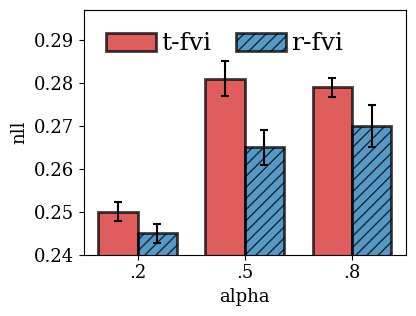

In [39]:
from matplotlib.ticker import FormatStrFormatter

yaxis_digit=2
nexp = 5
alpha_=0.75
#ticklabel = lambda_list_0_fsvi
ticklabel = ['.2','.5','.8']

ind = 3*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
width = 1  # the width of the bars    


##---------------------------------------------------------------------------------------------------------
#figsiz=(5,3.5)
#fig,ax =plt.subplots(figsize=figsiz)



#color_nll, color_aucroc='blue','red'
#color_nll, color_aucroc='lightblue','coral'
#color_nll, color_aucroc='tab:red','tab:blue'
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

ticksiz=13
labelsiz=13

##---------------------------------------------------------------------------------------------------------


figsiz=(4.5,3.5)
#fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
#fig.subplots_adjust(wspace=0, hspace=0)
fig,axs =plt.subplots(figsize=figsiz)

##----------------------------------------------
## fsvi
##----------------------------------------------

#metric_list = np.array(nll_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]

mean,std =nll_fsvi[:,-2], nll_fsvi[:,-1]
axs.bar(ind + -.55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='t-fvi',
)




##----------------------------------------------
## bma
##----------------------------------------------

# metric_list = np.array(nll_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
mean,std =nll_bma[:,-2], nll_bma[:,-1]

axs.bar(ind + .55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='r-fvi',
)



## figure configurations
#labelsiz = 13
axs.set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs.tick_params(axis='both', which='major', labelsize=ticksiz)



# axs[1].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

# #labelsiz = 15
# axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
# #axs[0].set_ylabel('nll',fontsize=labelsiz)
# #


##label
#labelsiz = 15
#axs.set_xlabel('regularization effect',fontsize=labelsiz)
axs.set_xlabel('alpha',fontsize=labelsiz)
axs.set_ylabel('nll',fontsize=labelsiz)


##ylim
axs.set_ylim([0.240,0.297])


axs.legend(fontsize=fontsiz,loc='upper left',ncol=2, handletextpad = .2, handlelength=2, columnspacing=1.,frameon=False)



fig.tight_layout()

filename='nll_{}_v7_alpha'.format(modelname)

formatted = 'pdf'
savefigname = savedir + filename + '.' + formatted
plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
print(savefigname + '_saved')

plt.show()



./figs/exp1/aucroc_together_v7_alpha.pdf_saved


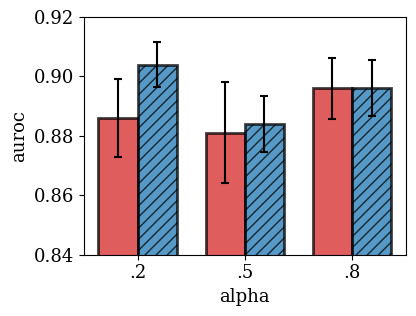

In [47]:
from matplotlib.ticker import FormatStrFormatter

yaxis_digit=2
nexp = 5
alpha_=0.75
#ticklabel = lambda_list_0_fsvi
ticklabel = ['.2','.5','.8']

ind = 3*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
width = 1  # the width of the bars    


##---------------------------------------------------------------------------------------------------------
#figsiz=(5,3.5)
#fig,ax =plt.subplots(figsize=figsiz)



#color_nll, color_aucroc='blue','red'
#color_nll, color_aucroc='lightblue','coral'
#color_nll, color_aucroc='tab:red','tab:blue'
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

ticksiz=13
labelsiz=13

##---------------------------------------------------------------------------------------------------------


figsiz=(4.5,3.5)
#fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
#fig.subplots_adjust(wspace=0, hspace=0)
fig,axs =plt.subplots(figsize=figsiz)

##----------------------------------------------
## fsvi
##----------------------------------------------

#metric_list = np.array(nll_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]

mean,std =aucroc_fsvi[:,-2], aucroc_fsvi[:,-1]

axs.bar(ind + -.55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='t-fvi',
)




##----------------------------------------------
## bma
##----------------------------------------------

# metric_list = np.array(nll_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
mean,std =aucroc_bma[:,-2], aucroc_bma[:,-1]

axs.bar(ind + .55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='r-fvi',
)



## figure configurations
#labelsiz = 13
axs.set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs.tick_params(axis='both', which='major', labelsize=ticksiz)
#plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

#axs.grid(True)   

# axs[1].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

# #labelsiz = 15
# axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
# #axs[0].set_ylabel('nll',fontsize=labelsiz)
# #


##label
#labelsiz = 15
#axs.set_xlabel('regularization effect',fontsize=labelsiz)
axs.set_xlabel('alpha',fontsize=labelsiz)
axs.set_ylabel('auroc',fontsize=labelsiz)


##ylim
axs.set_ylim([0.84,0.92])


#axs.legend(fontsize=fontsiz,loc='upper left',ncol=2, handletextpad = .2, handlelength=2, columnspacing=1.,frameon=False)



fig.tight_layout()

filename='aucroc_{}_v7_alpha'.format(modelname)

formatted = 'pdf'
savefigname = savedir + filename + '.' + formatted
plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
print(savefigname + '_saved')

plt.show()



./figs/exp1/inent_together_v7_alpha.pdf_saved


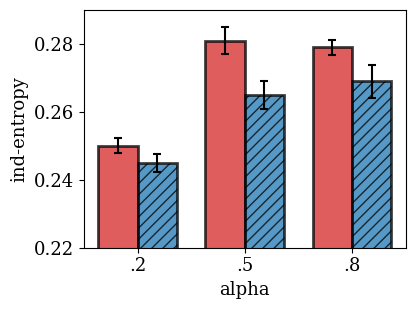

In [35]:
from matplotlib.ticker import FormatStrFormatter

yaxis_digit=2
nexp = 5
alpha_=0.75
#ticklabel = lambda_list_0_fsvi
ticklabel = ['.2','.5','.8']

ind = 3*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
width = 1  # the width of the bars    


##---------------------------------------------------------------------------------------------------------
#figsiz=(5,3.5)
#fig,ax =plt.subplots(figsize=figsiz)



#color_nll, color_aucroc='blue','red'
#color_nll, color_aucroc='lightblue','coral'
#color_nll, color_aucroc='tab:red','tab:blue'
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

ticksiz=13
labelsiz=13

##---------------------------------------------------------------------------------------------------------


figsiz=(4.5,3.5)
#fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
#fig.subplots_adjust(wspace=0, hspace=0)
fig,axs =plt.subplots(figsize=figsiz)

##----------------------------------------------
## fsvi
##----------------------------------------------

#metric_list = np.array(nll_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]

mean,std = inent_fsvi[:,-2], inent_fsvi[:,-1]

axs.bar(ind + -.55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='fvi',
)




##----------------------------------------------
## bma
##----------------------------------------------

# metric_list = np.array(nll_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
mean,std =inent_bma[:,-2], inent_bma[:,-1]

axs.bar(ind + .55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='r-fvi',
)



## figure configurations
#labelsiz = 13
axs.set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs.tick_params(axis='both', which='major', labelsize=ticksiz)



# axs[1].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

# #labelsiz = 15
# axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
# #axs[0].set_ylabel('nll',fontsize=labelsiz)
# #


##label
#labelsiz = 15
#axs.set_xlabel('regularization effect',fontsize=labelsiz)
axs.set_xlabel('alpha',fontsize=labelsiz)
axs.set_ylabel('ind-entropy',fontsize=labelsiz)


##ylim
axs.set_ylim([0.22,0.29])


#axs.legend(fontsize=fontsiz,loc='upper left',ncol=2, handletextpad = .2, handlelength=2, columnspacing=1.,frameon=False)



fig.tight_layout()

filename='inent_{}_v7_alpha'.format(modelname)

formatted = 'pdf'
savefigname = savedir + filename + '.' + formatted
plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
print(savefigname + '_saved')

plt.show()



./figs/exp1/outent_together_v7_alpha.pdf_saved


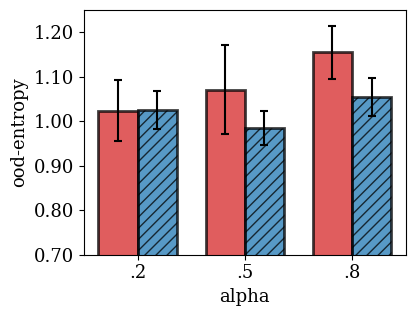

In [37]:
from matplotlib.ticker import FormatStrFormatter

yaxis_digit=2
nexp = 5
alpha_=0.75
#ticklabel = lambda_list_0_fsvi
ticklabel = ['.2','.5','.8']

ind = 3*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
width = 1  # the width of the bars    


##---------------------------------------------------------------------------------------------------------
#figsiz=(5,3.5)
#fig,ax =plt.subplots(figsize=figsiz)



#color_nll, color_aucroc='blue','red'
#color_nll, color_aucroc='lightblue','coral'
#color_nll, color_aucroc='tab:red','tab:blue'
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

ticksiz=13
labelsiz=13

##---------------------------------------------------------------------------------------------------------


figsiz=(4.5,3.5)
#fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
#fig.subplots_adjust(wspace=0, hspace=0)
fig,axs =plt.subplots(figsize=figsiz)

##----------------------------------------------
## fsvi
##----------------------------------------------

#metric_list = np.array(nll_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]

mean,std = outent_fsvi[:,-2], outent_fsvi[:,-1]

axs.bar(ind + -.55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='fvi',
)




##----------------------------------------------
## bma
##----------------------------------------------

# metric_list = np.array(nll_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
mean,std = outent_bma[:,-2], outent_bma[:,-1]

axs.bar(ind + .55*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='r-fvi',
)



## figure configurations
#labelsiz = 13
axs.set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs.tick_params(axis='both', which='major', labelsize=ticksiz)



# axs[1].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

# #labelsiz = 15
# axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
# #axs[0].set_ylabel('nll',fontsize=labelsiz)
# #


##label
#labelsiz = 15
#axs.set_xlabel('regularization effect',fontsize=labelsiz)
axs.set_xlabel('alpha',fontsize=labelsiz)
axs.set_ylabel('ood-entropy',fontsize=labelsiz)


##ylim
axs.set_ylim([0.70,1.25])


#axs.legend(fontsize=fontsiz,loc='upper left',ncol=2, handletextpad = .2, handlelength=2, columnspacing=1.,frameon=False)



fig.tight_layout()

filename='outent_{}_v7_alpha'.format(modelname)

formatted = 'pdf'
savefigname = savedir + filename + '.' + formatted
plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
print(savefigname + '_saved')

plt.show()



In [41]:
# from matplotlib.ticker import FormatStrFormatter

# yaxis_digit=2
# nexp = 5
# alpha_=0.75
# ticklabel = lambda_list_0_fsvi
# ind = 5*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
# width = 1  # the width of the bars    


# ##---------------------------------------------------------------------------------------------------------
# #figsiz=(5,3.5)
# #fig,ax =plt.subplots(figsize=figsiz)



# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'
# #color_nll, color_aucroc='tab:red','tab:blue'
# error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# # ticksiz=13
# # labelsiz=13

# ##---------------------------------------------------------------------------------------------------------


# figsiz=(6.5,4)
# fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
# #fig.subplots_adjust(wspace=0, hspace=0)

# ##----------------------------------------------
# ## fsvi
# ##----------------------------------------------
# metric_list = np.array(outent_list_0_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[0].bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(outent_list_1_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[0].bar(ind - 0*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(outent_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[0].bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )

# ## figure configurations
# #labelsiz = 13
# axs[0].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[0].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[0].tick_params(axis='both', which='major', labelsize=ticksiz)









# # ##----------------------------------------------
# # ## bma
# # ##----------------------------------------------
# metric_list = np.array(outent_list_0_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[1].bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         hatch = '///',        
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(outent_list_1_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[1].bar(ind - 0*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         hatch = '///',        
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(outent_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# axs[1].bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         hatch = '///',        
#         edgecolor='black',                
#         label='alpha=0.8',
# )

# axs[1].set_xticks( ind , ticklabel)
# # plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# # axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
# axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
# axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

# #labelsiz = 15
# axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
# #axs[0].set_ylabel('nll',fontsize=labelsiz)
# #






# ##label
# #labelsiz = 15
# axs[0].set_xlabel('regularization effect',fontsize=labelsiz)
# axs[0].set_ylabel('outdist entropy',fontsize=labelsiz)


# ##ylim
# axs[0].set_ylim([0.80,1.25])



# fig.tight_layout()

# filename='outent_{}_v4'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



In [80]:
# from matplotlib.ticker import FormatStrFormatter

# yaxis_digit=2
# nexp = 5
# alpha_=0.75
# ticklabel = lambda_list_0_fsvi
# ind = 10*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
# width = 1  # the width of the bars    


# ##---------------------------------------------------------------------------------------------------------
# figsiz=(5,3.5)
# #fig,ax =plt.subplots(figsize=figsiz)



# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'
# #color_nll, color_aucroc='tab:red','tab:blue'
# error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# ticksiz=13
# labelsiz=15

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)


# ##----------------------------------------------
# ## fsvi
# ##----------------------------------------------
# metric_list = np.array(aucroc_list_0_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(aucroc_list_1_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(aucroc_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )



# ##----------------------------------------------
# ## bma
# ##----------------------------------------------
# metric_list = np.array(aucroc_list_0_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.2',        
# )

# metric_list = np.array(aucroc_list_1_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.5',
# )

# metric_list = np.array(aucroc_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         hatch = '///',
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.8',
# )




# ## figure configurations



# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('auroc',fontsize=labelsiz)




# plt.ylim([0.80,0.93])




# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper center',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# filename='auroc_{}_v3'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



In [43]:
# from matplotlib.ticker import FormatStrFormatter

# # yaxis_digit=2
# # nexp = 3
# # ticklabel = lambda_list_0
# # ind = 1.25*np.arange(len(nll_list_0))  # the x locations for the groups
# # width = 0.75  # the width of the bars    
# # color_nll, color_aucroc='tab:red','tab:blue'
# # error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)
# # ticksiz=13
# # labelsiz=15



# ##---------------------------------------------------------------------------------------------------------
# figsiz=(5,3.5)
# #fig,ax =plt.subplots(figsize=figsiz)



# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)



# metric_list = np.array(aucroc_list_0)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(aucroc_list_1)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(aucroc_list_2)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )

# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('auroc',fontsize=labelsiz)




# plt.ylim([0.82,0.92])


# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper left',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# #savedir='./'
# #filename='nll_{}'.format(modelname)
# filename='auroc_{}_v2'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



## indist entropy

./figs/exp1/inent_together_v4.pdf_saved


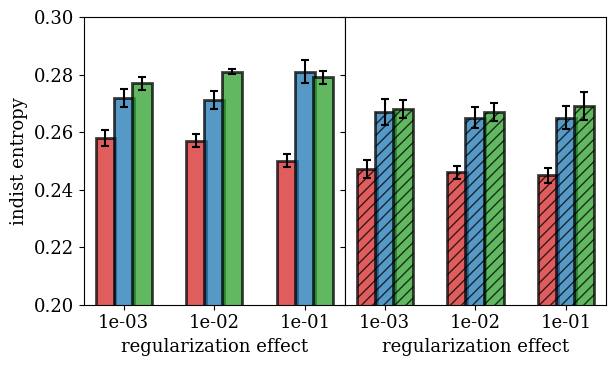

In [87]:
from matplotlib.ticker import FormatStrFormatter

yaxis_digit=2
nexp = 5
alpha_=0.75
ticklabel = lambda_list_0_fsvi
ind = 5*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
width = 1  # the width of the bars    


##---------------------------------------------------------------------------------------------------------
#figsiz=(5,3.5)
#fig,ax =plt.subplots(figsize=figsiz)



#color_nll, color_aucroc='blue','red'
#color_nll, color_aucroc='lightblue','coral'
#color_nll, color_aucroc='tab:red','tab:blue'
error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# ticksiz=13
# labelsiz=13

##---------------------------------------------------------------------------------------------------------


figsiz=(6.5,4)
fig,axs =plt.subplots(ncols=2,figsize=figsiz,sharey=True, gridspec_kw={'hspace': 0.0, 'wspace': 0.0})
#fig.subplots_adjust(wspace=0, hspace=0)

##----------------------------------------------
## fsvi
##----------------------------------------------
metric_list = np.array(inent_list_0_fsvi)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[0].bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2. ,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        edgecolor='black',                
        label='alpha=0.2',        
)

metric_list = np.array(inent_list_1_fsvi)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[0].bar(ind - 0*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        edgecolor='black',                
        label='alpha=0.5',
)

metric_list = np.array(inent_list_2_fsvi)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[0].bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:green',
        alpha=alpha_,
        edgecolor='black',                
        label='alpha=0.8',
)

## figure configurations
#labelsiz = 13
axs[0].set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs[0].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs[0].tick_params(axis='both', which='major', labelsize=ticksiz)









# ##----------------------------------------------
# ## bma
# ##----------------------------------------------
metric_list = np.array(inent_list_0_bma)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[1].bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2. ,
        error_kw=error_kw_shared,
        color = 'tab:red',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='alpha=0.2',        
)

metric_list = np.array(inent_list_1_bma)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[1].bar(ind - 0*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:blue',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='alpha=0.5',
)

metric_list = np.array(inent_list_2_bma)
mean = metric_list[:,0]
std  = metric_list[:,1]
axs[1].bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
        linewidth=2.,
        error_kw=error_kw_shared,
        color = 'tab:green',
        alpha=alpha_,
        hatch = '///',        
        edgecolor='black',                
        label='alpha=0.8',
)

axs[1].set_xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# axs[0].set_gca().yaxis.get_offset_text().set_size(ticksiz)
axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))
axs[1].tick_params(axis='both', which='major', labelsize=ticksiz)

#labelsiz = 15
axs[1].set_xlabel('regularization effect',fontsize=labelsiz)
#axs[0].set_ylabel('nll',fontsize=labelsiz)
#axs[0].set_ylim([0.24,0.295])




##label
#labelsiz = 15
axs[0].set_xlabel('regularization effect',fontsize=labelsiz)
axs[0].set_ylabel('indist entropy',fontsize=labelsiz)


##ylim
axs[0].set_ylim([0.20,0.30])




fig.tight_layout()

filename='inent_{}_v4'.format(modelname)

formatted = 'pdf'
savefigname = savedir + filename + '.' + formatted
plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
print(savefigname + '_saved')

plt.show()



In [88]:
# from matplotlib.ticker import FormatStrFormatter

# yaxis_digit=2
# nexp = 5
# alpha_=0.75
# ticklabel = lambda_list_0_fsvi
# ind = 10*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
# width = 1  # the width of the bars    


# ##---------------------------------------------------------------------------------------------------------
# figsiz=(5,3.5)
# #fig,ax =plt.subplots(figsize=figsiz)



# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'
# #color_nll, color_aucroc='tab:red','tab:blue'
# error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# ticksiz=13
# labelsiz=15

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)


# ##----------------------------------------------
# ## fsvi
# ##----------------------------------------------
# metric_list = np.array(inent_list_0_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(inent_list_1_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(inent_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )



# ##----------------------------------------------
# ## bma
# ##----------------------------------------------
# metric_list = np.array(inent_list_0_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.2',        
# )

# metric_list = np.array(inent_list_1_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.5',
# )

# metric_list = np.array(inent_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         hatch = '///',
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.8',
# )




# ## figure configurations



# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('indist entropy',fontsize=labelsiz)




# plt.ylim([0.22,0.30])




# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper center',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# filename='indistent_{}_v3'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



## entropy difference

In [161]:
# diffent_list_0_fsvi

[(0.739, 0.202), (0.743, 0.235), (0.774, 0.155)]

In [89]:
# from matplotlib.ticker import FormatStrFormatter

# yaxis_digit=2
# nexp = 5
# alpha_=0.75
# ticklabel = lambda_list_0_fsvi
# ind = 10*np.arange(len(nll_list_0_fsvi))  # the x locations for the groups
# width = 1  # the width of the bars    


# ##---------------------------------------------------------------------------------------------------------
# figsiz=(5,3.5)
# #fig,ax =plt.subplots(figsize=figsiz)



# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'
# #color_nll, color_aucroc='tab:red','tab:blue'
# error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# ticksiz=13
# labelsiz=15

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)


# ##----------------------------------------------
# ## fsvi
# ##----------------------------------------------
# metric_list = np.array(diffent_list_0_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(diffent_list_1_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(diffent_list_2_fsvi)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )



# ##----------------------------------------------
# ## bma
# ##----------------------------------------------
# metric_list = np.array(diffent_list_0_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 1*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.2',        
# )

# metric_list = np.array(diffent_list_1_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 2*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         hatch = '///',        
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.5',
# )

# metric_list = np.array(diffent_list_2_bma)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 3*width, mean , 1.1*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         hatch = '///',
#         alpha=0.9*alpha_,
#         edgecolor='black',                
#         #label='alpha=0.8',
# )




# ## figure configurations



# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('diff entropy',fontsize=labelsiz)




# plt.ylim([0.60,0.93])




# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper left',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# filename='diffent_{}_v3'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



In [160]:
# from matplotlib.ticker import FormatStrFormatter

# # yaxis_digit=2
# # nexp = 3



# # ##---------------------------------------------------------------------------------------------------------
# # figsiz=(5,3.5)
# # #fig,ax =plt.subplots(figsize=figsiz)

# # ticklabel = lambda_list_0
# # ind = 1.25*np.arange(len(nll_list_0))  # the x locations for the groups
# # #ind = 4*np.arange(len(nll_list_0))  # the x locations for the groups

# # width = .75  # the width of the bars    


# # #color_nll, color_aucroc='blue','red'
# # #color_nll, color_aucroc='lightblue','coral'
# # color_nll, color_aucroc='tab:red','tab:blue'
# # error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# # ticksiz=13
# # labelsiz=15

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)



# metric_list = np.array(inent_list_0)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(inent_list_1)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(inent_list_2)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )



# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('entropy',fontsize=labelsiz)




# plt.ylim([0.20,0.30])




# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper left',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# #savedir='./'
# #filename='nll_{}'.format(modelname)
# #filename='nll_{}'.format(modelname)
# filename='inent_{}_v2'.format(modelname)

# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# print(savefigname + '_saved')

# plt.show()



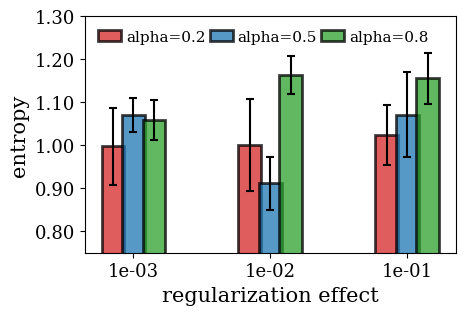

In [68]:
# from matplotlib.ticker import FormatStrFormatter

# # yaxis_digit=2
# # nexp = 3



# # ##---------------------------------------------------------------------------------------------------------
# # figsiz=(5,3.5)
# # #fig,ax =plt.subplots(figsize=figsiz)

# # ticklabel = lambda_list_0
# # ind = 1.25*np.arange(len(nll_list_0))  # the x locations for the groups
# # #ind = 4*np.arange(len(nll_list_0))  # the x locations for the groups

# # width = .75  # the width of the bars    


# # #color_nll, color_aucroc='blue','red'
# # #color_nll, color_aucroc='lightblue','coral'
# # color_nll, color_aucroc='tab:red','tab:blue'
# # error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)

# # ticksiz=13
# # labelsiz=15

# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)



# metric_list = np.array(outent_list_0)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.2',        
# )

# metric_list = np.array(outent_list_1)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.5',
# )

# metric_list = np.array(outent_list_2)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0.225, mean , 0.5*width, yerr= 1*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:green',
#         alpha=alpha_,
#         edgecolor='black',                
#         label='alpha=0.8',
# )



# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('entropy',fontsize=labelsiz)




# plt.ylim([0.75,1.3])




# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper left',ncol=3, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)



# fig.tight_layout()

# #savedir='./'
# #filename='nll_{}'.format(modelname)
# # filename='nll_{}'.format(modelname)

# # formatted = 'pdf'
# # savefigname = savedir + filename + '.' + formatted
# #plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# #print(savefigname + '_saved')

# plt.show()



In [2]:
# list_tmp = [(OrderedDict([('', AttrDict({})),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.001_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.921, 0.918, 0.915, 0.917, 0.92]),
#                             ('nll', [0.256, 0.266, 0.263, 0.256, 0.249]),
#                             ('ece', [0.012, 0.013, 0.014, 0.013, 0.013]),
#                             ('aucroc1', [0.818, 0.871, 0.915, 0.862, 0.919]),
#                             ('indent1', [0.256, 0.266, 0.262, 0.256, 0.249]),
#                             ('outdent1', [0.714, 0.959, 1.208, 0.864, 1.24]),
#                             ('fdivin',
#                              [(0.024, 0.009),
#                               (0.025, 0.009),
#                               (0.025, 0.009),
#                               (0.025, 0.009),
#                               (0.024, 0.008)]),
#                             ('fdivout',
#                              [(0.077, 0.014),
#                               (0.101, 0.015),
#                               (0.133, 0.016),
#                               (0.117, 0.016),
#                               (0.117, 0.016)]),
#                             ('rfdivin',
#                              [(0.038, 0.016),
#                               (0.04, 0.016),
#                               (0.039, 0.015),
#                               (0.039, 0.015),
#                               (0.038, 0.015)]),
#                             ('rfdivout',
#                              [(0.122, 0.026),
#                               (0.158, 0.028),
#                               (0.21, 0.031),
#                               (0.187, 0.031),
#                               (0.187, 0.03)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.01_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.922, 0.921, 0.916, 0.919, 0.916]),
#                             ('nll', [0.253, 0.251, 0.264, 0.256, 0.26]),
#                             ('ece', [0.012, 0.01, 0.011, 0.013, 0.011]),
#                             ('aucroc1', [0.866, 0.838, 0.88, 0.866, 0.947]),
#                             ('indent1', [0.253, 0.251, 0.264, 0.256, 0.26]),
#                             ('outdent1', [0.862, 0.78, 0.994, 0.91, 1.455]),
#                             ('fdivin',
#                              [(0.025, 0.009),
#                               (0.024, 0.009),
#                               (0.026, 0.009),
#                               (0.026, 0.009),
#                               (0.025, 0.009)]),
#                             ('fdivout',
#                              [(0.099, 0.015),
#                               (0.063, 0.013),
#                               (0.118, 0.016),
#                               (0.096, 0.015),
#                               (0.114, 0.016)]),
#                             ('rfdivin',
#                              [(0.039, 0.016),
#                               (0.038, 0.016),
#                               (0.041, 0.017),
#                               (0.042, 0.017),
#                               (0.04, 0.016)]),
#                             ('rfdivout',
#                              [(0.158, 0.029),
#                               (0.097, 0.022),
#                               (0.188, 0.03),
#                               (0.151, 0.027),
#                               (0.185, 0.032)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.1_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.921, 0.927, 0.917, 0.922, 0.92]),
#                             ('nll', [0.251, 0.245, 0.259, 0.244, 0.253]),
#                             ('ece', [0.012, 0.015, 0.012, 0.013, 0.012]),
#                             ('aucroc1', [0.833, 0.906, 0.917, 0.897, 0.879]),
#                             ('indent1', [0.251, 0.245, 0.259, 0.244, 0.252]),
#                             ('outdent1', [0.774, 1.124, 1.224, 1.058, 0.939]),
#                             ('fdivin',
#                              [(0.025, 0.009),
#                               (0.023, 0.008),
#                               (0.025, 0.009),
#                               (0.025, 0.009),
#                               (0.024, 0.009)]),
#                             ('fdivout',
#                              [(0.1, 0.015),
#                               (0.099, 0.015),
#                               (0.118, 0.016),
#                               (0.11, 0.016),
#                               (0.121, 0.016)]),
#                             ('rfdivin',
#                              [(0.039, 0.016),
#                               (0.035, 0.014),
#                               (0.039, 0.016),
#                               (0.039, 0.016),
#                               (0.038, 0.016)]),
#                             ('rfdivout',
#                              [(0.156, 0.028),
#                               (0.158, 0.029),
#                               (0.189, 0.031),
#                               (0.174, 0.03),
#                               (0.194, 0.031)])]))]),
#  OrderedDict([('', AttrDict({})),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.001_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.91, 0.915, 0.914, 0.913, 0.917]),
#                             ('nll', [0.272, 0.276, 0.282, 0.274, 0.259]),
#                             ('ece', [0.014, 0.016, 0.015, 0.013, 0.012]),
#                             ('aucroc1', [0.867, 0.888, 0.862, 0.909, 0.897]),
#                             ('indent1', [0.272, 0.275, 0.282, 0.274, 0.259]),
#                             ('outdent1', [0.96, 1.078, 1.0, 1.209, 1.101]),
#                             ('fdivin',
#                              [(0.028, 0.009),
#                               (0.028, 0.009),
#                               (0.026, 0.009),
#                               (0.028, 0.009),
#                               (0.026, 0.009)]),
#                             ('fdivout',
#                              [(0.082, 0.014),
#                               (0.141, 0.017),
#                               (0.094, 0.015),
#                               (0.118, 0.017),
#                               (0.122, 0.016)]),
#                             ('rfdivin',
#                              [(0.043, 0.016),
#                               (0.044, 0.017),
#                               (0.041, 0.016),
#                               (0.043, 0.016),
#                               (0.041, 0.016)]),
#                             ('rfdivout',
#                              [(0.128, 0.026),
#                               (0.228, 0.033),
#                               (0.149, 0.028),
#                               (0.193, 0.033),
#                               (0.196, 0.032)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.01_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.913, 0.914, 0.915, 0.916, 0.919]),
#                             ('nll', [0.276, 0.274, 0.279, 0.265, 0.259]),
#                             ('ece', [0.013, 0.013, 0.014, 0.013, 0.013]),
#                             ('aucroc1', [0.855, 0.854, 0.808, 0.856, 0.904]),
#                             ('indent1', [0.276, 0.274, 0.279, 0.265, 0.259]),
#                             ('outdent1', [0.861, 0.921, 0.723, 0.906, 1.144]),
#                             ('fdivin',
#                              [(0.028, 0.009),
#                               (0.025, 0.009),
#                               (0.027, 0.009),
#                               (0.027, 0.009),
#                               (0.025, 0.008)]),
#                             ('fdivout',
#                              [(0.094, 0.015),
#                               (0.104, 0.015),
#                               (0.118, 0.016),
#                               (0.109, 0.016),
#                               (0.107, 0.016)]),
#                             ('rfdivin',
#                              [(0.044, 0.017),
#                               (0.04, 0.016),
#                               (0.042, 0.016),
#                               (0.042, 0.017),
#                               (0.038, 0.015)]),
#                             ('rfdivout',
#                              [(0.147, 0.027),
#                               (0.165, 0.029),
#                               (0.186, 0.03),
#                               (0.174, 0.03),
#                               (0.173, 0.031)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.1_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.912, 0.911, 0.912, 0.902, 0.916]),
#                             ('nll', [0.276, 0.28, 0.281, 0.297, 0.271]),
#                             ('ece', [0.011, 0.013, 0.013, 0.012, 0.013]),
#                             ('aucroc1', [0.897, 0.854, 0.822, 0.932, 0.899]),
#                             ('indent1', [0.276, 0.28, 0.281, 0.297, 0.271]),
#                             ('outdent1', [1.136, 0.901, 0.766, 1.412, 1.14]),
#                             ('fdivin',
#                              [(0.024, 0.008),
#                               (0.026, 0.009),
#                               (0.028, 0.009),
#                               (0.031, 0.01),
#                               (0.027, 0.009)]),
#                             ('fdivout',
#                              [(0.113, 0.016),
#                               (0.081, 0.014),
#                               (0.128, 0.016),
#                               (0.137, 0.017),
#                               (0.103, 0.015)]),
#                             ('rfdivin',
#                              [(0.038, 0.015),
#                               (0.041, 0.016),
#                               (0.044, 0.017),
#                               (0.049, 0.018),
#                               (0.041, 0.016)]),
#                             ('rfdivout',
#                              [(0.183, 0.031),
#                               (0.127, 0.026),
#                               (0.202, 0.031),
#                               (0.223, 0.033),
#                               (0.164, 0.029)])]))]),
#  OrderedDict([('', AttrDict({})),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.001_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.911, 0.914, 0.912, 0.91, 0.915]),
#                             ('nll', [0.279, 0.27, 0.286, 0.278, 0.275]),
#                             ('ece', [0.016, 0.013, 0.013, 0.012, 0.013]),
#                             ('aucroc1', [0.849, 0.907, 0.89, 0.867, 0.885]),
#                             ('indent1', [0.279, 0.27, 0.286, 0.278, 0.274]),
#                             ('outdent1', [0.929, 1.216, 1.112, 0.964, 1.067]),
#                             ('fdivin',
#                              [(0.028, 0.009),
#                               (0.027, 0.009),
#                               (0.028, 0.009),
#                               (0.028, 0.009),
#                               (0.026, 0.009)]),
#                             ('fdivout',
#                              [(0.105, 0.015),
#                               (0.112, 0.016),
#                               (0.124, 0.016),
#                               (0.099, 0.015),
#                               (0.103, 0.016)]),
#                             ('rfdivin',
#                              [(0.043, 0.016),
#                               (0.043, 0.017),
#                               (0.045, 0.017),
#                               (0.045, 0.017),
#                               (0.041, 0.017)]),
#                             ('rfdivout',
#                              [(0.166, 0.029),
#                               (0.18, 0.031),
#                               (0.197, 0.031),
#                               (0.155, 0.028),
#                               (0.164, 0.03)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.01_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.911, 0.91, 0.913, 0.914, 0.91]),
#                             ('nll', [0.283, 0.283, 0.279, 0.28, 0.278]),
#                             ('ece', [0.014, 0.016, 0.013, 0.012, 0.011]),
#                             ('aucroc1', [0.902, 0.888, 0.905, 0.916, 0.877]),
#                             ('indent1', [0.283, 0.283, 0.279, 0.28, 0.278]),
#                             ('outdent1', [1.196, 1.082, 1.196, 1.308, 1.031]),
#                             ('fdivin',
#                              [(0.028, 0.009),
#                               (0.029, 0.009),
#                               (0.027, 0.009),
#                               (0.028, 0.009),
#                               (0.028, 0.009)]),
#                             ('fdivout',
#                              [(0.106, 0.016),
#                               (0.138, 0.017),
#                               (0.128, 0.017),
#                               (0.111, 0.016),
#                               (0.102, 0.016)]),
#                             ('rfdivin',
#                              [(0.044, 0.016),
#                               (0.045, 0.017),
#                               (0.042, 0.017),
#                               (0.045, 0.017),
#                               (0.044, 0.017)]),
#                             ('rfdivout',
#                              [(0.168, 0.03),
#                               (0.225, 0.033),
#                               (0.207, 0.032),
#                               (0.178, 0.031),
#                               (0.165, 0.03)])])),
#               ('fbresnet20_logstd-8_tmppeak1.0_pstdout10.0_nfs10_reglam0.1_topk10_nepr0.01_ltelbo_mixctTrue_nfs100',
#                OrderedDict([('acc', [0.913, 0.915, 0.91, 0.911, 0.913]),
#                             ('nll', [0.277, 0.274, 0.288, 0.281, 0.273]),
#                             ('ece', [0.012, 0.013, 0.014, 0.013, 0.013]),
#                             ('aucroc1', [0.88, 0.89, 0.864, 0.922, 0.923]),
#                             ('indent1', [0.277, 0.274, 0.288, 0.281, 0.273]),
#                             ('outdent1', [1.052, 1.078, 1.014, 1.327, 1.306]),
#                             ('fdivin',
#                              [(0.028, 0.009),
#                               (0.027, 0.009),
#                               (0.028, 0.009),
#                               (0.028, 0.009),
#                               (0.027, 0.009)]),
#                             ('fdivout',
#                              [(0.089, 0.015),
#                               (0.121, 0.016),
#                               (0.109, 0.016),
#                               (0.109, 0.016),
#                               (0.107, 0.016)]),
#                             ('rfdivin',
#                              [(0.045, 0.017),
#                               (0.043, 0.016),
#                               (0.046, 0.018),
#                               (0.045, 0.017),
#                               (0.042, 0.016)]),
#                             ('rfdivout',
#                              [(0.14, 0.027),
#                               (0.196, 0.032),
#                               (0.173, 0.03),
#                               (0.175, 0.031),
#                               (0.173, 0.031)])]))]))
# ]

NameError: name 'OrderedDict' is not defined

NameError: name 'lambda_list' is not defined

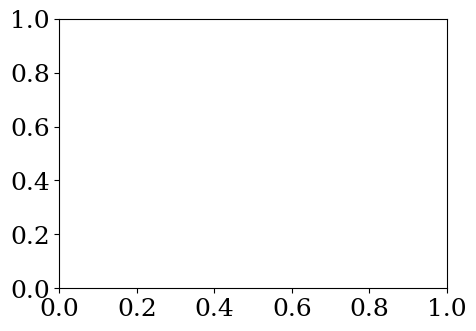

In [72]:
# from matplotlib.ticker import FormatStrFormatter

# yaxis_digit=2
# nexp = 3



# ##---------------------------------------------------------------------------------------------------------
# figsiz=(5,3.5)
# fig,ax =plt.subplots(figsize=figsiz)


# ticklabel = lambda_list
# ind = 1.25*np.arange(len(nll_list))  # the x locations for the groups
# width = 0.75  # the width of the bars    


# #color_nll, color_aucroc='blue','red'
# #color_nll, color_aucroc='lightblue','coral'
# color_nll, color_aucroc='tab:red','tab:blue'
# error_kw_shared =dict(lw=1.5, capsize=3, capthick=1.5)


# metric_list = np.array(nll_list)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind , mean , width, yerr= 2*std/np.sqrt(nexp), 
#         linewidth=3 ,
#         error_kw=error_kw_shared,
#         color = color_nll,
#         alpha=0.5,
# )




# ticksiz = 11
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('log likelihood',fontsize=labelsiz)

# #plt.ylim([0.20,0.35])

# fig.tight_layout()

# #savedir='./'
# filename='nll_{}'.format(modelname)
# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# plt.show()
# print(savefigname + '_saved')








# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)


# metric_list = np.array(aucroc_list)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind , mean , width, yerr= 2*std/np.sqrt(nexp), 
#         linewidth=3 ,
#         error_kw=error_kw_shared,
#         color = color_aucroc,
#         alpha=0.5

# )


# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('aucroc',fontsize=labelsiz)

# #plt.ylim([0.80,0.95])


# fig.tight_layout()

# #savedir='./'
# filename='aucroc_{}'.format(modelname)
# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# plt.show()
# print(savefigname + '_saved')






# ##---------------------------------------------------------------------------------------------------------


# #figsiz=(6,4)
# fig,ax =plt.subplots(figsize=figsiz)


# metric_list = np.array(inent_list)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind - 0.2, mean , 0.5*width, yerr= 2*std/np.sqrt(nexp), 
#         linewidth=2. ,
#         error_kw=error_kw_shared,
#         color = 'tab:red',
#         alpha=0.5,
#         label='in-train',        
# )

# metric_list = np.array(outent_list)
# mean = metric_list[:,0]
# std  = metric_list[:,1]
# plt.bar(ind + 0.2, mean , 0.5*width, yerr= 2*std/np.sqrt(nexp), 
#         linewidth=2.,
#         error_kw=error_kw_shared,
#         color = 'tab:blue',
#         alpha=0.5,
#         label='out-train',
# )


# #labelsiz = 13
# plt.xticks( ind , ticklabel)
# plt.tick_params(axis='both', which='major', labelsize= ticksiz)
# plt.gca().yaxis.get_offset_text().set_size(ticksiz)
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.{}f'.format(yaxis_digit)))


# #labelsiz = 15
# plt.xlabel('regularization effect',fontsize=labelsiz)
# plt.ylabel('entropy',fontsize=labelsiz)

# #plt.ylim([0.80,0.95])
# fongsiz=13
# plt.legend(fontsize=fongsiz-2,loc='upper left',ncol=2, handletextpad = .3, handlelength=1.5, columnspacing= .3,frameon=False)


# fig.tight_layout()

# #savedir='./'
# filename='entropy_{}'.format(modelname)
# formatted = 'pdf'
# savefigname = savedir + filename + '.' + formatted
# plt.savefig( savefigname , format=formatted, dpi=1000, bbox_inches='tight')
# plt.show()
# print(savefigname + '_saved')



In [16]:
## 09/05/23 adv inputs 

In [16]:
# model.usediagcov = True
nfsample=20

## check the effectiveness of the proposed model performance 

In [17]:
# saved_file['optimizer_dict']['param_groups'][0]

#model.params_p_logstd[0]

iter_train = iter(trainloader)
iter_val   = iter(valloader)
iter_test  = iter(testloader)
iter_ood   = iter(oodloader_v1)


In [92]:
#xt,yt = next(iter_train)
#xt,yt = next(iter_val)
xt,yt = next(iter_test)
#xt,yt = next(iter_ood)


#xt
#yt


In [93]:
# nfsample=50

model.temperature_peak

0.9

In [94]:
import torch.nn.functional as F
from torch.distributions.categorical import Categorical

param_q_mean, param_q_logstd  = list(model.stochastic_nn.parameters()) ,  list(model.params_q_logstd)             
qf_mean_x , qf_diagcov_x, h_x  = model.compute_funcdist_wo_jacobian( xt.cuda(), param_q_mean, param_q_logstd )   #without jacobian computation         
qf_std_x                      = torch.sqrt(qf_diagcov_x)


#param_p_mean,param_p_logstd = i_th_saved['updated_p_params']
#pf_mean_x , pf_diagcov_x, _  = model.compute_funcdist_wo_jacobian( xt.cuda(), param_p_mean,param_p_logstd )   #without jacobian computation         
pf_mean_x , pf_diagcov_x, _   = model.compute_funcdist_wo_jacobian( xt.cuda(), model.params_p_mean,model.params_p_logstd )   #without jacobian computation         
pf_std_x                      = model.priorstdout*torch.sqrt(pf_diagcov_x)


logits_sample_qf = model.build_logit_samples_from_fdist(qf_mean_x,qf_std_x,nfsample=nfsample)

# #topk=3
# topk=3
# phat_nominator   =  qf_mean_x.detach().clone()      
# #nmh_distance     = -model.priorstdout*model.mixture_module.compute_mh_distance_batch(h_x, overclass=True).detach().clone()       
# nmh_distance     =  -model.mixture_module.compute_mh_distance_batch(h_x, overclass=True).detach().clone()       
# #phat_denominator =  torch.sqrt( 1 + torch.pi/8 * qf_diagcov_x.detach().clone()     )*torch.sqrt(nmh_distance)    ## best performance     
# phat_denominator =  torch.sqrt( 1 + torch.pi/8 * qf_diagcov_x.detach().clone()     )*torch.sqrt(nmh_distance)    ## best performance     
# #phat_denominator =  torch.sqrt( 1 + torch.pi/8 * nmh_distance )         
# #phat_denominator =  torch.sqrt( 1 + torch.pi/8 *qf_diagcov_x.detach().clone()*nmh_distance )         
# post_logits_phat =  phat_nominator / phat_denominator


# # nmh_distance     = -self.priorstdout*self.mixture_module.compute_mh_distance_batch(h_x, overclass=True).detach().clone()       
# # phat_denominator =  torch.sqrt( 1 + torch.pi/8 * qf_diagcov_x.detach().clone()     )*nmh_distance         

# # (2): topk<10            
# post_logits_phat_topk,logit_idx = post_logits_phat.topk(topk, dim=1)
# cat_h_sparse_samples = Categorical(logits=post_logits_phat_topk).sample((nfsample,))
# cat_h_samples = torch.cat([ logit_idx[range(len(logit_idx)),i_samples].view(1,-1) for i_samples in cat_h_sparse_samples],dim=0)                               
                    




# (2): topk<10            
topk=3
phat_nominator   =  qf_mean_x      
#nmh_distance     =  -model.mixture_module.compute_mh_distance_batch(h_x, overclass=True, usenormalize=True)      
nmh_distance     =  -model.mixture_module.compute_mh_distance_batch(h_x, overclass=True, usenormalize=False)   
   
#nmh_distance     = -model.priorstdout*model.mixture_module.compute_mh_distance_batch(h_x, overclass=True).detach().clone()       
#phat_denominator =  torch.sqrt( 1 + torch.pi/8 * qf_diagcov_x.detach().clone()     )*torch.sqrt(nmh_distance)    ## best performance     
#phat_denominator =  torch.sqrt( 1 + torch.pi/8 * qf_diagcov_x.detach().clone()     )*torch.sqrt(1 + nmh_distance+ nmh_distance**2/2)    ## best performance     
phat_denominator =  torch.sqrt( 1 + torch.pi/8 * nmh_distance )         
#phat_denominator =  torch.sqrt( 1 + torch.pi/8 * (nmh_distance  + qf_diagcov_x.detach().clone()) )         
#phat_denominator =  torch.sqrt( 1 + torch.pi/8 * (nmh_distance*qf_diagcov_x.detach().clone()) )         
#phat_denominator =  torch.sqrt( 1 + torch.pi/8 *qf_diagcov_x.detach().clone()*nmh_distance )         
# #phat_denominator =  torch.sqrt( 1 + torch.pi/8 * nmh_distance )     

post_logits_phat = ( phat_nominator / phat_denominator ).detach().clone() 
post_logits_phat_topk,logit_idx = post_logits_phat.topk(topk, dim=1)



# # (3): topk<10            
# topk=3
# phat_nominator   =  qf_mean_x.detach().clone()      
# logit_idx = phat_nominator.topk(topk, dim=1)[1]
# nmh_distance     =  -model.mixture_module.compute_mh_distance_batch(h_x, overclass=True).detach().clone()       
# #phat_denominator =  torch.sqrt( 1 + torch.pi/8 * nmh_distance )*torch.sqrt(nmh_distance)          
# phat_denominator =  torch.sqrt( 1 + torch.pi/8 * (nmh_distance  + qf_diagcov_x.detach().clone()) )         
# post_logits_phat_topk = torch.gather(phat_nominator,1,logit_idx) / torch.gather(phat_denominator,1,logit_idx)





cat_h_sparse_samples = Categorical(logits=post_logits_phat_topk).sample((nfsample,))
cat_h_samples = torch.cat([ logit_idx[range(len(logit_idx)),i_samples].view(1,-1) for i_samples in cat_h_sparse_samples],dim=0)                               







                    
## get logits samples from posterior
peak_idx            =  torch.cat( [F.one_hot(i_sample, num_classes=logits_sample_qf.shape[-1])[None] for i_sample in cat_h_samples] , dim = 0 ) 
soft_idx            =  1- peak_idx
temperature_samples =  peak_idx/model.temperature_peak + soft_idx/model.temperature_soft
logits_sample_qf      =  logits_sample_qf * temperature_samples


## get logits from prior
logits_sample_pf = model.build_logit_samples_from_fdist(pf_mean_x,pf_std_x,nfsample=nfsample)


In [95]:
#qf_diagcov_x
#nmh_distance.sqrt()
torch.topk(phat_denominator,dim=-1,k=3,largest=False)[0][::4]

tensor([[ 6.0415, 11.2389, 11.6203],
        [ 2.5296,  8.8693,  9.3843],
        [ 5.4039,  7.5909,  7.6261],
        [ 4.0702,  7.5605,  8.3551],
        [ 5.4530, 10.8519, 11.0300],
        [ 4.5262,  6.0824,  6.1760],
        [ 5.3876, 11.2424, 11.5553],
        [ 3.7763,  9.6228,  9.9104],
        [ 3.2916,  6.6223,  8.4584],
        [ 3.0046,  8.2957,  8.3903],
        [ 4.1242, 10.4242, 10.4936],
        [ 5.1945, 10.1831, 10.7754],
        [ 3.8947,  8.4041,  9.3440],
        [ 3.5736,  8.2047,  8.9605],
        [ 5.2730,  6.3002,  6.4849],
        [ 5.6639,  5.7477,  5.7884],
        [ 3.0474,  9.4423,  9.4671],
        [ 4.1297,  9.8769,  9.8830],
        [ 2.3459,  8.1254,  8.1495],
        [ 2.2935,  7.7406,  8.3570],
        [ 3.3783,  8.2978,  8.7311],
        [ 4.4487,  9.5236, 10.0750],
        [ 3.5565,  6.0176,  7.6861],
        [ 5.6237, 12.5743, 12.7090],
        [ 4.9704,  8.9490,  9.3192],
        [ 3.8665,  5.5528,  6.9989],
        [ 3.1418,  5.9268,  6.9203],
 

In [96]:
# cat_h_samples[:,0]
qf_diagcov_x

tensor([[0.0006, 0.0005, 0.0005,  ..., 0.0006, 0.0005, 0.0007],
        [0.0003, 0.0003, 0.0003,  ..., 0.0003, 0.0004, 0.0003],
        [0.0003, 0.0003, 0.0003,  ..., 0.0002, 0.0003, 0.0002],
        ...,
        [0.0003, 0.0004, 0.0003,  ..., 0.0004, 0.0003, 0.0003],
        [0.0004, 0.0003, 0.0003,  ..., 0.0003, 0.0004, 0.0004],
        [0.0003, 0.0003, 0.0003,  ..., 0.0003, 0.0003, 0.0003]],
       device='cuda:0', grad_fn=<AddBackward0>)

In [97]:
for i in range(20):
    print(cat_h_samples[:,2*i])

#model.priorstdout

tensor([6, 6, 6, 6, 6, 4, 6, 6, 6, 8, 6, 6, 6, 6, 6, 6, 4, 6, 6, 6],
       device='cuda:0')
tensor([5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       device='cuda:0')
tensor([8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8],
       device='cuda:0')
tensor([0, 0, 5, 3, 5, 5, 0, 3, 5, 5, 3, 3, 3, 3, 5, 5, 0, 3, 3, 3],
       device='cuda:0')
tensor([5, 5, 5, 5, 2, 5, 5, 5, 2, 5, 5, 5, 5, 5, 5, 2, 2, 5, 5, 5],
       device='cuda:0')
tensor([0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       device='cuda:0')
tensor([1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       device='cuda:0')
tensor([0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       device='cuda:0')
tensor([4, 4, 4, 4, 7, 4, 4, 4, 4, 4, 0, 4, 4, 4, 4, 4, 4, 4, 4, 4],
       device='cuda:0')
tensor([9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9],
       device='cuda:0')
tensor([9, 3, 9, 9, 9, 3, 9, 9, 9, 9, 1, 9, 1, 9, 3, 1, 9, 9, 9, 9],
 

## compute acc mm

In [98]:
# #post_logits_phat.shape, 
# cat_h_samples.shape, logits_sample.shape, logits_sample_pf.shape
digit = 3

## get yhat
yhat_cat = cat_h_samples
yhat_qf = logits_sample_qf.max(dim=-1)[1]
yhat_pf = logits_sample_pf.max(dim=-1)[1]
param_kde_pf  = model.compute_fdist(xt.cuda(),topk=10)[1]


## evaluation
acc_yhat_cat  = np.array([(i_sample == yt.cuda()).sum().item()/128 for i_sample in yhat_cat]).round(digit)
acc_yhat_qf  = np.array([(i_sample == yt.cuda()).sum().item()/128 for i_sample  in yhat_qf]).round(digit)
acc_yhat_pf  = np.array([(i_sample == yt.cuda()).sum().item()/128 for i_sample  in yhat_pf]).round(digit)
acc_yhat_kde = np.array(( param_kde_pf[0].max(dim=-1)[1] == yt.cuda() ).sum().item() / 128 ).round(digit)

In [99]:
digit = 3

print( 'acc_yhat_cat \t: {}'.format(  (acc_yhat_cat .mean().round(digit),acc_yhat_cat.std().round(digit))     ))
print( 'acc_yhat_qf \t: {}'.format(  (acc_yhat_qf.mean().round(digit),acc_yhat_qf.std().round(digit))     ))
print( 'acc_yhat_pf \t: {}'.format(  (acc_yhat_pf.mean().round(digit),acc_yhat_pf.std().round(digit))     ))
print( 'acc_yhat_kde \t: {}'.format(  (acc_yhat_kde , 0.) ))


#yhat_cat

#cat_h_samples
# logits_sample_pf = model.build_logit_samples_from_fdist(pf_mean_x,pf_std_x,nfsample=nfsample)


acc_yhat_cat 	: (0.786, 0.031)
acc_yhat_qf 	: (0.911, 0.009)
acc_yhat_pf 	: (0.913, 0.008)
acc_yhat_kde 	: (0.906, 0.0)


In [100]:
# # model.params_p_logstd[0]
# qf_std_x,pf_std_x

In [ ]:
# # param_qf, param_pf, _  = model.compute_fdist(xt.cuda(),topk=10)
# # ( param_pf[0].max(dim=-1)[1] == yt.cuda() ).sum().item() / 128 ,   ( param_qf[0].max(dim=-1)[1] == yt.cuda() ).sum().item() / 128

# param_qf, param_pf, _  = model.compute_fdist(xt.cuda(),topk=10)

# pf_mean_x,pf_diagcov_x = param_pf[0], param_pf[1]**2
# logit_phat = pf_mean_x / torch.sqrt( 1 + torch.pi/8 * pf_diagcov_x )

# logit_phat_topk,logit_idx = logit_phat.topk(topk, dim=1)
# cat_h_sparse_samples = Categorical(logits=logit_phat_topk).sample((nfsample,))
# cat_h_samples = torch.cat([ logit_idx[range(len(logit_idx)),i_samples].view(1,-1) for i_samples in cat_h_sparse_samples],dim=0)






# print( 'pf mean by kde :\t {:.3f}'.format( ( param_pf[0].max(dim=-1)[1] == yt.cuda() ).sum().item() / 128 ) )
# print( 'qf mean        :\t {:.3f}'.format( ( param_qf[0].max(dim=-1)[1] == yt.cuda() ).sum().item() / 128 ) )
# print( 'pf hat mean by kde:\t {:.3f}'.format( ( logit_phat.max(dim=-1)[1] == yt.cuda() ).sum().item() / 128 ) )


# multi_sample_mh = np.array([(i_sample == yt.cuda()).sum().item()/128 for i_sample in cat_h_samples]).round(digit)
# print( 'pf hat sampling h: {}'.format(  (multi_sample_mh.mean().round(digit),multi_sample_mh.std().round(digit))     ))




In [ ]:
model.temperature_peak = 0.5